# 03 — MLP sur embeddings vs baseline naïve (regex)

Objectif : mesurer ce qu'apporte un MLP entraîné sur les embeddings Sentence-BERT des descriptions
par rapport à une approche **sans apprentissage** à base de mots-clés.

| Modèle | Entrée | Apprentissage |
|---|---|---|
| **Regex manuelle** | description nettoyée | aucun : mots-clés écrits a priori |
| **Regex TF-IDF** | description + code | vocabulaire tiré de la TF-IDF par tag (train), réglé sur val |
| **Régression logistique** | embeddings (768 dimensions) | linéaire, one-vs-rest : référence intermédiaire |
| **Régression logistique réglée** | embeddings, PCA à k dimensions | k et `C` choisis par validation croisée |
| **MLP** | embeddings (768 dimensions) | 1 couche cachée, **8 sorties sigmoïdes** + BCE (multi-label, pas de softmax) |

Protocole :
- **Split** : train 70 % / val 15 % / test 15 %, stratifié multi-label, avec une seed fixe.
- **Seuils** : un seuil de décision par tag, optimisé sur la **validation**.
- **Évaluation** : uniquement sur le **test**.

In [1]:
import itertools
import logging
import sys
import time
from dataclasses import replace
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.baselines import TAG_PATTERNS, RegexTagger, fit_keyword_tagger
from src.config import SEED, TARGET_TAGS, LogRegConfig, MLPConfig, RegexConfig, TopicConfig, TuningConfig
from src.dataset import load_modeling_data
from src.embeddings import load_encoder
from src.evaluate import (
    apply_thresholds,
    bootstrap_macro_f1_diff,
    global_metrics,
    per_tag_metrics,
    tune_thresholds,
)
from src.linear import build_logreg, fit_predict_logreg
from src.mlp import predict_proba, train_mlp
from src.preprocessing import normalize_text
from src.split import build_label_matrix
from src.tuning import grid_search

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("httpx", "httpx2", "huggingface_hub", "sentence_transformers"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 150)

TOPIC_CFG = TopicConfig()
MLP_CFG = MLPConfig()
REGEX_CFG = RegexConfig()

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 12:33:39.255000 41173 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 1. Données, embeddings et split

In [2]:
# Nettoyage, embeddings (cache du notebook 02) et split : voir src/dataset.py
data = load_modeling_data(TOPIC_CFG)
df, x, y, pos = data.df, data.x, data.y, data.positions
print({name: arr.shape for name, arr in x.items()})

INFO src.preprocessing: Filtre langue : 4982 -> 4965 exemples


INFO src.preprocessing: Dédoublonnage : 4965 -> 4834 exemples


INFO src.embeddings: Embeddings chargés depuis /Users/ramzi/Documents/illuin-test/data/embeddings/all-mpnet-base-v2__prob_desc_description.npz


{'train': (3383, 768), 'val': (725, 768), 'test': (726, 768)}


In [3]:
# Contrôle de la stratification : prévalence de chaque tag par split
pd.DataFrame({name: arr.mean(axis=0) for name, arr in y.items()}, index=TARGET_TAGS).style.format("{:.1%}")

,train,val,test
math,28.5%,28.4%,28.5%
graphs,11.0%,10.9%,11.0%
strings,8.5%,8.4%,8.4%
number theory,7.0%,6.9%,7.0%
trees,6.4%,6.3%,6.3%
geometry,3.4%,3.3%,3.3%
games,2.1%,2.1%,2.1%
probabilities,1.9%,1.8%,1.9%


## 2. Baselines naïves : regex

Un tag est prédit dès qu'un de ses mots-clés apparaît. Deux vocabulaires sont comparés :
1. **Regex manuelle** (référence) : mots-clés écrits a priori, appliqués à la description.
2. **Regex TF-IDF** : vocabulaire tiré de la **TF-IDF par tag** (notebook 02, `src/class_tfidf.py`), appliquée à la
   **description et au code source**.

In [4]:
train_df, val_df, test_df = (df.iloc[pos[name]] for name in ("train", "val", "test"))

pd.Series(TAG_PATTERNS, name="pattern").to_frame()

,pattern
math,\b(?:sum|product|divisible|modulo|equation|formula|integer)\b
graphs,\b(?:graph|vertex|vertices|edges?|roads?|cities)\b
strings,\b(?:strings?|substrings?|palindromes?|letters?|characters?)\b
number theory,\b(?:primes?|gcd|lcm|divisors?|coprime|modulo)\b
trees,\b(?:trees?|rooted|subtrees?|leaf|leaves)\b
geometry,\b(?:polygons?|circles?|angles?|coordinates|triangles?|segments?)\b
games,\b(?:game|players?|winner|wins|optimally)\b
probabilities,\b(?:probability|expected|expectation|random)\b


In [5]:
predictions = {"regex_manuel": RegexTagger().predict(test_df["text_clean"])}
per_tag_metrics(y["test"], predictions["regex_manuel"], TARGET_TAGS).round(2)

,precision,recall,f1,support
math,0.37,0.49,0.42,207
graphs,0.40,0.50,0.45,80
strings,0.42,0.90,0.57,61
number theory,0.45,0.51,0.48,51
trees,0.59,0.63,0.61,46
geometry,0.24,0.75,0.36,24
games,0.17,1.00,0.30,15
probabilities,0.55,0.86,0.67,14


### Regex à vocabulaire TF-IDF (description + code)

**Pipeline**

```
ENTRAÎNEMENT (train uniquement)
  description brute ─► nettoyage ─► lemmatisation ─┐
                                                   ├─► TF-IDF par tag ─► top-k termes / tag ─► regex
  code brut ─────────────────────────────────────┘     (lift vs « aucun tag »)

INFÉRENCE (val, test, CLI)
  description brute ─► nettoyage ─► lemmatisation ─► regex description ─┐
  code brut ────────────────────────────────────► regex code ─────────┴─► OU (tags où le code aide)
```

- **Dictionnaire construit sur le train uniquement.** Celui du notebook 02, calculé sur tout le jeu, inclut le test.
- **Description lemmatisée, à l'entraînement comme à l'inférence** (`prepare_description`, appelée par le tagger lui-même) :
  le terme appris *vertex* reconnaît « vertices » dans un nouvel énoncé, puisque celui-ci est lemmatisé avant la regex.
- **Code non lemmatisé** : le lemmatiseur WordNet altérerait les identifiants.
- **Sélection des termes** : pour chaque tag, les **k meilleurs termes** parmi ceux au moins `min_lift` fois plus marqués que
  dans le groupe « aucun tag cible ». Ce filtre écarte les termes fréquents partout (`array`, `ans`, `list`…). Il est plus
  strict pour le code (×5 au lieu de ×2), car beaucoup de tokens de code sont génériques (`pop`, `add`, `set`).
- **Code utilisé tag par tag** : la règle « description OU code » n'est activée que pour les tags où elle bat la description
  seule en F1 **de validation**.

**Réglage** : `k_desc`, `k_code` et `desc_min_lift` sont choisis sur la validation (grille ci-dessous). Le test n'est
utilisé qu'à la fin.

In [6]:
train_labels = build_label_matrix(train_df["tags"])
grid = []
for desc_min_lift, k_desc, k_code in itertools.product((2, 3, 5, 10), (2, 3, 5, 10), (1, 2, 3, 5, 10)):
    cfg = replace(REGEX_CFG, desc_min_lift=desc_min_lift, k_desc=k_desc, k_code=k_code)
    tagger = fit_keyword_tagger(train_df["prob_desc_description"], train_df["source_code"], train_labels, cfg)
    tagger.choose_code_usage(val_df["prob_desc_description"], val_df["source_code"], y["val"])
    val_pred = tagger.predict(val_df["prob_desc_description"], val_df["source_code"])
    grid.append(
        {"desc_min_lift": desc_min_lift, "k_desc": k_desc, "k_code": k_code,
         "val_macro_f1": global_metrics(y["val"], val_pred)["macro_f1"]}
    )
grid = pd.DataFrame(grid).sort_values("val_macro_f1", ascending=False, ignore_index=True)
best = grid.iloc[0]
regex_cfg = replace(
    REGEX_CFG, desc_min_lift=float(best["desc_min_lift"]), k_desc=int(best["k_desc"]), k_code=int(best["k_code"])
)
print("Retenu sur la validation :", regex_cfg)
grid.head(10).round(3)

Retenu sur la validation : RegexConfig(k_desc=2, k_code=5, desc_min_lift=5.0, code_min_lift=5.0)


,desc_min_lift,k_desc,k_code,val_macro_f1
0,5,2,5,0.501
1,5,2,3,0.497
2,2,2,5,0.497
3,5,2,2,0.494
4,5,2,10,0.493
5,2,2,3,0.493
6,5,2,1,0.493
7,2,2,10,0.492
8,2,2,2,0.490
9,2,2,1,0.488


In [7]:
keyword_tagger = fit_keyword_tagger(train_df["prob_desc_description"], train_df["source_code"], train_labels, regex_cfg)
keyword_tagger.choose_code_usage(val_df["prob_desc_description"], val_df["source_code"], y["val"])

pd.DataFrame(
    {
        "termes description": {t: ", ".join(w) for t, w in keyword_tagger.desc_terms.items()},
        "termes code": {t: ", ".join(w) for t, w in keyword_tagger.code_terms.items()},
        "code utilisé": dict(zip(TARGET_TAGS, keyword_tagger.use_code)),
    }
)

,termes description,termes code,code utilisé
math,"divisible, divisor","pow, lru_cache, primes, fact, factor",True
graphs,"connected, graph","edges, node, visited, stack, popleft",True
strings,"string, letter","ord, chr, replace, 97, lower",False
number theory,"divisor, greatest","gcd, pow, prime, primes, factor",True
trees,"tree, vertex","parent, node, dfs, root, tree",False
geometry,"plane, point","x1, x2, y1, y2, points",False
games,"play optimally, optimally","Alice, Bob, odd, even, win",False
probabilities,"probability, expected","pow, random, 998244353, prob, randint",False


In [8]:
# Apport de chaque source : description seule, code seul, description OU code (pour tous les tags), règle retenue
rows = {}
for split, frame in (("val", val_df), ("test", test_df)):
    sources = keyword_tagger.predict_by_source(frame["prob_desc_description"], frame["source_code"])
    sources["retenue (code par tag)"] = keyword_tagger.predict(frame["prob_desc_description"], frame["source_code"])
    for name, pred in sources.items():
        rows[(name, split)] = global_metrics(y[split], pred)["macro_f1"]
pd.Series(rows).unstack().round(3).rename(columns=lambda s: f"Macro-F1 {s}")

,Macro-F1 test,Macro-F1 val
code,0.282,0.281
description,0.511,0.471
description OU code,0.441,0.427
retenue (code par tag),0.518,0.501


In [9]:
predictions["regex_tfidf"] = keyword_tagger.predict(test_df["prob_desc_description"], test_df["source_code"])
pd.concat(
    {
        "manuel": per_tag_metrics(y["test"], predictions["regex_manuel"], TARGET_TAGS),
        "tf-idf": per_tag_metrics(y["test"], predictions["regex_tfidf"], TARGET_TAGS),
    },
    axis=1,
).round(2)

manuel                         tf-idf                     
              precision recall    f1 support precision recall    f1 support
math               0.37   0.49  0.42     207      0.59   0.21  0.31     207
graphs             0.40   0.50  0.45      80      0.42   0.60  0.49      80
strings            0.42   0.90  0.57      61      0.45   0.85  0.59      61
number theory      0.45   0.51  0.48      51      0.40   0.65  0.49      51
trees              0.59   0.63  0.61      46      0.39   0.63  0.48      46
geometry           0.24   0.75  0.36      24      0.17   0.54  0.26      24
games              0.17   1.00  0.30      15      0.67   0.80  0.73      15
probabilities      0.55   0.86  0.67      14      0.79   0.79  0.79      14

## 3. Référence linéaire : régression logistique sur les embeddings

8 régressions logistiques binaires indépendantes (one-vs-rest), régularisation L2 (`C=1`), classes pondérées
(`class_weight="balanced"`). Code : `src/linear.py`.

In [10]:
def fit_and_threshold(name: str, model) -> None:
    """Entraîne sur train, règle les seuils sur val, prédit le test."""
    model.fit(x["train"], y["train"])
    thresholds[name] = tune_thresholds(y["val"], model.predict_proba(x["val"]))
    predictions[name] = apply_thresholds(model.predict_proba(x["test"]), thresholds[name])


thresholds = {}
fit_and_threshold("logreg", build_logreg(LogRegConfig()))
per_tag_metrics(y["test"], predictions["logreg"], TARGET_TAGS).round(2)

,precision,recall,f1,support
math,0.46,0.55,0.50,207
graphs,0.51,0.57,0.54,80
strings,0.60,0.62,0.61,61
number theory,0.51,0.57,0.54,51
trees,0.54,0.72,0.62,46
geometry,0.56,0.75,0.64,24
games,0.85,0.73,0.79,15
probabilities,0.58,0.79,0.67,14


### 3b. Réduction de dimension : PCA + régression logistique

Hypothèse : 768 variables pour ~3 400 exemples d'entraînement, c'est beaucoup. Une PCA en amont réduit le nombre de
paramètres (8 × (k + 1) au lieu de 8 × 769) et pourrait limiter le sur-apprentissage.

**Protocole de sélection**
- **Grille** : nombre de composantes k × régularisation `C`.
- **Validation** : croisée à 5 folds sur **train + val**. Le test n'est jamais vu.
- **Critère** : Macro-AP (aire sous la courbe précision-rappel moyenne par tag), indépendante des seuils.
- **Pas de fuite** : la PCA est dans le pipeline, donc ajustée sur chaque fold d'entraînement uniquement.

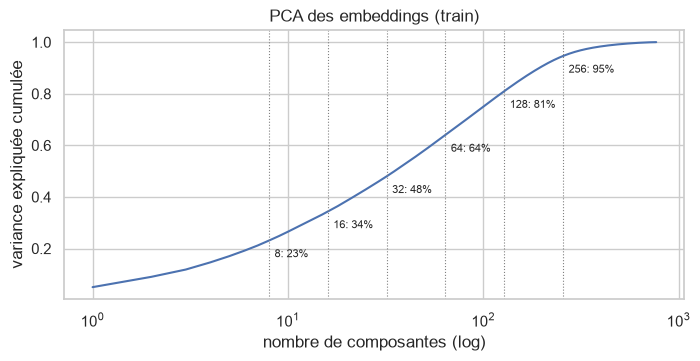

In [11]:
# Variance expliquée : combien de composantes pour résumer les embeddings ?
pca_full = PCA(random_state=SEED).fit(x["train"])
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative)
for k in (8, 16, 32, 64, 128, 256):
    ax.axvline(k, color="gray", linestyle=":", linewidth=0.8)
    ax.annotate(f"{k}: {cumulative[k - 1]:.0%}", (k, cumulative[k - 1]), textcoords="offset points", xytext=(4, -12), fontsize=8)
ax.set(xscale="log", xlabel="nombre de composantes (log)", ylabel="variance expliquée cumulée", title="PCA des embeddings (train)")
plt.show()

In [12]:
TUNING_CFG = TuningConfig()
x_dev, y_dev = data.dev()

logreg_grid = grid_search(
    dict(TUNING_CFG.logreg_grid),
    lambda params: partial(fit_predict_logreg, replace(LogRegConfig(), **params)),
    x_dev,
    y_dev,
    TUNING_CFG.n_splits,
)
logreg_grid.head(10).round(4)

INFO src.tuning: {'n_components': 8, 'C': 0.01} -> Macro-AP 0.4408


INFO src.tuning: {'n_components': 8, 'C': 0.1} -> Macro-AP 0.4424


INFO src.tuning: {'n_components': 8, 'C': 1.0} -> Macro-AP 0.4381


INFO src.tuning: {'n_components': 8, 'C': 10.0} -> Macro-AP 0.4337


INFO src.tuning: {'n_components': 16, 'C': 0.01} -> Macro-AP 0.5144


INFO src.tuning: {'n_components': 16, 'C': 0.1} -> Macro-AP 0.5265


... (19 outputs left out)

INFO src.tuning: {'n_components': None, 'C': 0.1} -> Macro-AP 0.5932


INFO src.tuning: {'n_components': None, 'C': 1.0} -> Macro-AP 0.5904


INFO src.tuning: {'n_components': None, 'C': 10.0} -> Macro-AP 0.5702


,n_components,C,cv_macro_ap,cv_std,seconds
0,NaN,0.10,0.5932,0.0329,0.1924
1,256.0,0.10,0.5924,0.0327,0.3268
2,NaN,1.00,0.5904,0.0334,0.2658
3,256.0,1.00,0.5861,0.0327,0.3576
4,128.0,0.10,0.5860,0.0323,0.2156
5,NaN,0.01,0.5815,0.0363,0.1411
6,256.0,0.01,0.5806,0.0362,0.3161
7,64.0,0.10,0.5781,0.0341,0.1778
8,128.0,0.01,0.5775,0.0352,0.2039
9,128.0,1.00,0.5770,0.0332,0.2367


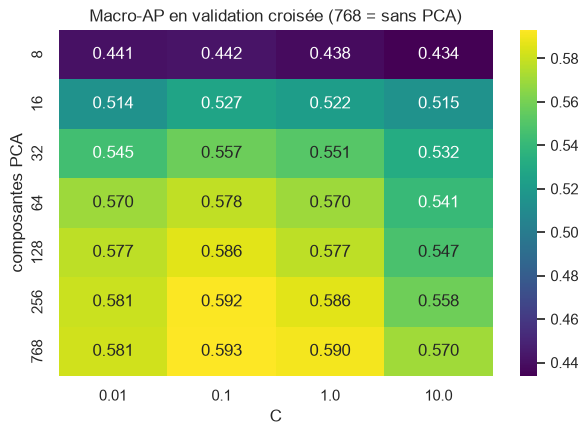

In [13]:
heatmap = logreg_grid.assign(n_components=logreg_grid["n_components"].fillna(768).astype(int)).pivot(
    index="n_components", columns="C", values="cv_macro_ap"
)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(heatmap, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set(title="Macro-AP en validation croisée (768 = sans PCA)", ylabel="composantes PCA")
plt.show()

In [14]:
best = logreg_grid.iloc[0]
best_n = None if pd.isna(best["n_components"]) else int(best["n_components"])
best_logreg_cfg = LogRegConfig(n_components=best_n, C=float(best["C"]))
print("Meilleure configuration :", best_logreg_cfg)

fit_and_threshold("logreg_tuned", build_logreg(best_logreg_cfg))
per_tag_metrics(y["test"], predictions["logreg_tuned"], TARGET_TAGS).round(2)

Meilleure configuration : LogRegConfig(n_components=None, C=0.1, max_iter=2000)


,precision,recall,f1,support
math,0.42,0.64,0.51,207
graphs,0.45,0.49,0.47,80
strings,0.50,0.82,0.62,61
number theory,0.54,0.49,0.52,51
trees,0.56,0.63,0.59,46
geometry,0.37,0.79,0.51,24
games,0.85,0.73,0.79,15
probabilities,0.61,0.79,0.69,14


## 4. MLP

Architecture : `768 → Linear(256) → ReLU → Dropout(0.3) → Linear(8)`, une sigmoïde par tag.

- **Loss** : `BCEWithLogitsLoss` avec `pos_weight = n_neg / n_pos` par tag, pour compenser le déséquilibre.
- **Entraînement** : AdamW, early stopping sur la loss de validation (patience 15). On restaure le meilleur modèle.

INFO src.mlp: Arrêt à l'epoch 21, meilleure val_loss=0.7147


Entraînement : 0.5s, 22 epochs


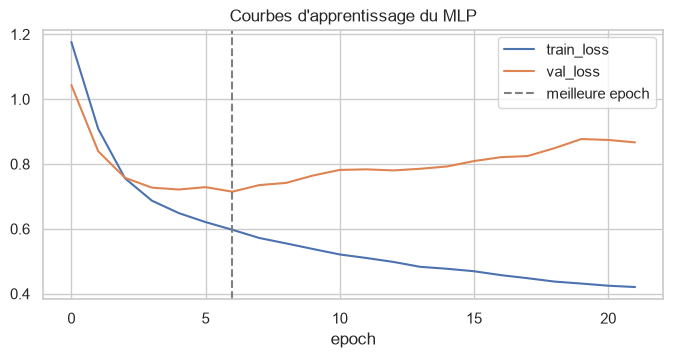

In [15]:
start = time.perf_counter()
mlp, history = train_mlp(x["train"], y["train"], x["val"], y["val"], MLP_CFG)
print(f"Entraînement : {time.perf_counter() - start:.1f}s, {len(history)} epochs")

fig, ax = plt.subplots(figsize=(8, 3.5))
history.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax, title="Courbes d'apprentissage du MLP")
ax.axvline(history["val_loss"].idxmin(), color="gray", linestyle="--", label="meilleure epoch")
ax.legend()
plt.show()

In [16]:
thresholds["mlp"] = tune_thresholds(y["val"], predict_proba(mlp, x["val"]))
predictions["mlp"] = apply_thresholds(predict_proba(mlp, x["test"]), thresholds["mlp"])

pd.DataFrame(thresholds, index=TARGET_TAGS).round(2).T

,math,graphs,strings,number theory,trees,geometry,games,probabilities
logreg,0.50,0.72,0.82,0.77,0.70,0.79,0.85,0.72
logreg_tuned,0.47,0.65,0.55,0.68,0.68,0.60,0.78,0.65
mlp,0.46,0.71,0.71,0.64,0.68,0.80,0.94,0.87


In [17]:
per_tag_metrics(y["test"], predictions["mlp"], TARGET_TAGS).round(2)

,precision,recall,f1,support
math,0.40,0.71,0.51,207
graphs,0.45,0.57,0.51,80
strings,0.51,0.75,0.61,61
number theory,0.36,0.67,0.47,51
trees,0.44,0.76,0.56,46
geometry,0.50,0.75,0.60,24
games,0.82,0.60,0.69,15
probabilities,0.69,0.64,0.67,14


## 5. Benchmark sur le test

In [18]:
benchmark = pd.DataFrame({name: global_metrics(y["test"], pred) for name, pred in predictions.items()}).T
benchmark.round(3)

,micro_f1,macro_f1,hamming_loss,jaccard_samples
regex_manuel,0.459,0.482,0.120,0.417
regex_tfidf,0.454,0.518,0.100,0.494
logreg,0.554,0.612,0.083,0.532
logreg_tuned,0.536,0.585,0.094,0.469
mlp,0.532,0.575,0.105,0.437


In [19]:
# L'écart de Macro-F1 entre deux modèles est-il significatif sur 726 exemples de test ?
pd.DataFrame(
    {
        f"{a} - {b}": bootstrap_macro_f1_diff(y["test"], predictions[a], predictions[b], TUNING_CFG.n_bootstrap)
        for a, b in [
            ("regex_tfidf", "regex_manuel"),
            ("logreg", "regex_tfidf"),
            ("logreg_tuned", "logreg"),
            ("logreg_tuned", "mlp"),
        ]
    }
).T.round(3)

,diff_mean,ci_low,ci_high,p_a_better
regex_tfidf - regex_manuel,0.036,-0.001,0.073,0.972
logreg - regex_tfidf,0.093,0.044,0.144,1.000
logreg_tuned - logreg,-0.027,-0.049,-0.005,0.009
logreg_tuned - mlp,0.011,-0.020,0.046,0.749


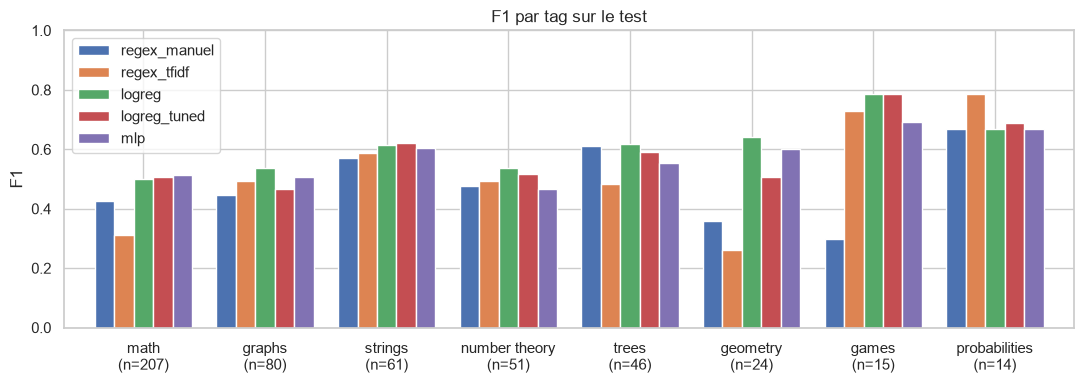

In [20]:
f1_by_tag = pd.DataFrame(
    {name: per_tag_metrics(y["test"], pred, TARGET_TAGS)["f1"] for name, pred in predictions.items()}
)
support = pd.Series(y["test"].sum(axis=0), index=TARGET_TAGS)

fig, ax = plt.subplots(figsize=(11, 4))
f1_by_tag.plot.bar(ax=ax, rot=0, width=0.8)
ax.set(title="F1 par tag sur le test", ylabel="F1", ylim=(0, 1))
ax.set_xticklabels([f"{t}\n(n={support[t]})" for t in TARGET_TAGS])
plt.tight_layout()
plt.show()

## 6. Analyse d'erreurs du MLP

In [21]:
errors = pd.DataFrame(
    {
        "faux positifs": ((predictions["mlp"] == 1) & (y["test"] == 0)).sum(axis=0),
        "faux négatifs": ((predictions["mlp"] == 0) & (y["test"] == 1)).sum(axis=0),
        "support": support,
    },
    index=TARGET_TAGS,
)
errors

,faux positifs,faux négatifs,support
math,223,59,207
graphs,56,34,80
strings,45,15,61
number theory,61,17,51
trees,45,11,46
geometry,18,6,24
games,2,6,15
probabilities,4,5,14


In [22]:
def show_errors(tag: str, kind: str, n: int = 3) -> None:
    """Affiche n faux positifs ('fp') ou faux négatifs ('fn') du MLP pour un tag."""
    k = TARGET_TAGS.index(tag)
    pred, true = predictions["mlp"][:, k], y["test"][:, k]
    mask = (pred == 1) & (true == 0) if kind == "fp" else (pred == 0) & (true == 1)
    for sample_id, row in test_df[mask].head(n).iterrows():
        print(f"[{sample_id}] tags={row['tags']}\n    {row['prob_desc_description'][:220]}\n")


print("=== math : faux négatifs ===")
show_errors("math", "fn")
print("=== number theory : faux positifs ===")
show_errors("number theory", "fp")

=== math : faux négatifs ===
[4] tags=['binary search', 'divide and conquer', 'brute force', 'math']
    Thanos wants to destroy the avengers base, but he needs to destroy the avengers along with their base.Let we represent their base with an array, where each position can be occupied by many avengers, but one avenger can o

[40] tags=['number theory', 'bitmasks', 'math', 'strings']
    You are given two strings $$$s$$$ and $$$t$$$, both consisting of exactly $$$k$$$ lowercase Latin letters, $$$s$$$ is lexicographically less than $$$t$$$.Let's consider list of all strings consisting of exactly $$$k$$$ l

[161] tags=['implementation', 'probabilities', 'math']
    Vasya and Kolya play a game with a string, using the following rules. Initially, Kolya creates a string s, consisting of small English letters, and uniformly at random chooses an integer k from a segment [0, len(s) - 1].

=== number theory : faux positifs ===
[38] tags=['dp', 'combinatorics', 'brute force']
    The Travelling S

## 7. Latence d'inférence (contrainte : < 10 s par exemple)

Mesure de bout en bout pour un exemple : nettoyage, embedding Sentence-BERT, puis MLP et seuils.
Le temps de chargement du modèle, payé une seule fois au démarrage, est mesuré à part.

In [23]:
start = time.perf_counter()
encoder = load_encoder(TOPIC_CFG.embedding_model)
load_time = time.perf_counter() - start

raw_text = test_df["prob_desc_description"].iloc[0]
encoder.encode([normalize_text(raw_text)])  # warm-up

latencies = []
for text in test_df["prob_desc_description"].iloc[:50]:
    start = time.perf_counter()
    emb = encoder.encode([normalize_text(text)], normalize_embeddings=True)
    apply_thresholds(predict_proba(mlp, emb), thresholds["mlp"])
    latencies.append(time.perf_counter() - start)

print(f"Chargement du modèle : {load_time:.1f}s (une fois)")
print(f"Latence par exemple : médiane {np.median(latencies) * 1000:.0f} ms, max {np.max(latencies) * 1000:.0f} ms")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13461.49it/s]

WARNING huggingface_hub.utils._http: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


Chargement du modèle : 1.1s (une fois)
Latence par exemple : médiane 15 ms, max 34 ms


## 8. Constats

**Benchmark (test, 726 exemples)**

| Modèle | Micro-F1 | Macro-F1 | Hamming loss | Jaccard |
|---|---|---|---|---|
| Regex manuelle (description) | 0.459 | 0.482 | 0.120 | 0.417 |
| Regex TF-IDF (description lemmatisée + code) | 0.454 | 0.518 | 0.100 | 0.494 |
| Régression logistique (768 dimensions, C=1) | **0.554** | **0.612** | **0.083** | **0.532** |
| Régression logistique réglée (768 dimensions, C=0.1) | 0.536 | 0.585 | 0.094 | 0.469 |
| MLP | 0.532 | 0.575 | 0.105 | 0.437 |

**Regex : vocabulaire manuel contre vocabulaire TF-IDF**
- **Le vocabulaire TF-IDF fait mieux que le vocabulaire manuel** : +3,6 points de Macro-F1. L'IC 95 % bootstrap
  [-0,1 ; +7,3] touche tout juste 0 (P = 0,97) : la tendance est nette, la significativité à la limite.
  Le vocabulaire est appris sur le train, sur des descriptions lemmatisées, avec `desc_min_lift=5`, k_desc=2 et k_code=5 réglés
  sur la validation.
- **Gros gains sur les tags dont le vocabulaire manuel était trop large** :
  - `games` : F1 de 0.30 à 0.73. La précision passe de 0.17 à 0.67, car *play optimally* est bien plus spécifique que *player* ou *wins*.
  - `probabilities` : F1 de 0.67 à 0.79.
- **Recul sur `math`** (F1 de 0.42 à 0.31), `trees` (0.61 à 0.48) et `geometry` (0.36 à 0.26). Pour ces tags, les termes
  « intuition métier » (*sum*, *subtree*, *angle*…) couvraient plus de cas que les 2 termes les plus marqués.
- **Apport de chaque source** (Macro-F1 test) :

  | Source | Macro-F1 test |
  |---|---|
  | Code seul | 0.28 |
  | Description seule | 0.51 |
  | Description OU code, pour tous les tags | 0.44 |
  | Règle retenue (code activé par tag) | **0.52** |

  Seul, le code est faible, et ajouté partout il dégrade le résultat : `pow` et `random` se déclenchent sur trop de solutions.
  Il n'aide que pour `math`, `graphs` et `number theory` (`gcd`, `primes`, `visited`, `popleft`…).
- **Lemmatisation** : elle fusionne les variantes (*vertex* / *vertices*), mais renforce aussi des bigrammes génériques
  (*positive integer*). D'où le filtre de spécificité plus strict pour la description (×5). Sans lemmatisation, on obtenait
  0.529 sur le test (0.510 en validation), un écart sans signification à cette taille d'échantillon. La version lemmatisée est
  gardée pour sa cohérence entre entraînement et inférence.
- **Les embeddings restent nettement au-dessus** : +9,3 points de Macro-F1 pour la régression logistique par rapport à la regex
  TF-IDF, IC 95 % [+4,4 ; +14,4].

**PCA : l'hypothèse « 768 variables, c'est trop » n'est pas vérifiée**
- La Macro-AP en validation croisée **augmente de façon monotone avec le nombre de composantes** (à C=0.1) :
  8 → 0.44, 16 → 0.53, 32 → 0.56, 64 → 0.58, 128 → 0.59, 256 → 0.59, 768 → 0.59.
- Il faut 194 composantes pour 90 % de la variance : l'information est **répartie** sur beaucoup de directions, et la PCA
  (non supervisée) jette des directions de faible variance qui peuvent pourtant porter du signal sur les tags.
- Le sur-apprentissage est déjà contrôlé par la **régularisation L2** : avec ~3 400 exemples pour 769 paramètres par tag,
  `C` joue le rôle que l'on attendait de la PCA, sans perte d'information.
- La validation croisée retient 768 dimensions sans PCA avec C=0.1, mais l'écart avec C=1 (0.593 contre 0.590) est
  **10 fois plus petit** que l'écart-type entre folds (0.033) : les deux sont statistiquement équivalents. Sur le test,
  C=1 fait mieux (0.612 contre 0.585), ce qui illustre la variance d'une sélection aussi fine. Les seuils réglés sur 725 exemples
  de validation, avec ~15 positifs pour les tags rares, en sont la principale source.
- **Décision** : on garde la configuration par défaut (768 dimensions, C=1) comme **benchmark** pour le MLP. C'est la plus
  simple, elle est équivalente en validation croisée, et c'est la plus difficile à battre sur le test.
- **Le MLP ne bat pas le modèle linéaire.** Il atteint son meilleur point de validation en quelques epochs puis sur-apprend
  (early stopping à l'epoch 21) : avec ~3 400 exemples d'entraînement, la couche cachée n'apporte pas de capacité utile
  sur des embeddings figés, déjà linéairement informatifs.
- **Le MLP prédit trop de tags** : `pos_weight` et des seuils bas (`math` 0.46) donnent un bon rappel mais une précision faible
  (`math` : 223 faux positifs pour 207 positifs réels), d'où son Hamming loss plus élevé que la régression logistique.
- **Les regex restent compétitives sur les tags lexicaux** : `probabilities` (F1 0.79 en TF-IDF, mieux que la régression
  logistique à 0.67) et `games` (0.73).
- **`math` reste le tag le plus dur** (F1 ≤ 0.51 pour tous les modèles) : tag conceptuel, peu lié au vocabulaire de l'énoncé.
  Les faux négatifs montrent des énoncés narratifs (« Thanos wants to destroy… ») où la notion mathématique n'apparaît
  que dans la solution.
- **Prudence statistique** : `games` (15) et `probabilities` (14) n'ont qu'une quinzaine d'exemples en test, donc leur F1
  varie de ±0.1 avec un seul exemple. Une validation croisée serait nécessaire pour conclure fermement sur ces tags.
- **Latence** : environ 18 ms par exemple (max 145 ms), plus 1,3 s de chargement du modèle une seule fois. C'est très loin de la
  contrainte de 10 s.

**Pistes**
1. Garder la **régression logistique** comme modèle de référence sur les embeddings : plus simple et meilleure.
2. Ajouter des **features de code** (`source_code` : imports, `%`, `gcd`, `math.`, structures de graphes…), qui devraient aider
   `math`, `number theory` et `graphs`.
3. Pour le MLP : réglage du learning rate et de la régularisation par validation croisée → notebook 04.